# 15 GHSL Jaipur Production and Unseen-City Model Evaluation

This notebook adapts the frozen multi-city production workflow used in <File>07_ghsl_pune_metropolitan_production.py</File> for Jaipur, then evaluates the frozen six-city Linear Regression model on Jaipur without retraining.

## Study window

- Jaipur seed: 75.7873° E, 26.9124° N
- Projection: ESRI:54009 (World Mollweide)
- 70 km × 70 km window
- Snapped 1 km extent: x 7,041,000–7,111,000 m; y 3,245,000–3,315,000 m
- Expected cells: 4,900 per epoch
- Epochs: 1975–2020 at five-year intervals

## Evaluation

The frozen model was trained only on Bengaluru, Hyderabad, Pune, Chennai, Mumbai, and Delhi NCR, with target years through 2010. Jaipur is never added to training. The primary result is Jaipur 2015→2020, which is unseen city plus unseen time.

All EC2/HDFS/Spark operations use `/content/drive/MyDrive/remote_exec.sh`. Run one cell at a time. Production Cell 7 is detached and may continue after Colab closes.

In [1]:
# ============================================================
# CELL 1: BOOTSTRAP
# ============================================================
from google.colab import drive
from pathlib import Path
import base64, csv, hashlib, json, os, shutil, subprocess, textwrap, time

drive.mount('/content/drive',force_remount=False)
D=Path('/content/drive/MyDrive');REMOTE_EXEC=D/'remote_exec.sh';DRIVE_KEY=D/'hadoop-hdfs.pem';LOCAL_KEY=Path('/content/hadoop-hdfs.pem')
ARTIFACT_ROOT=D/'GHSL_Urban_Growth_Model'/'jaipur_unseen_city_evaluation_v1'
TRAINING_MANIFEST=D/'GHSL_Urban_Growth_Model'/'model_training_v1'/'training_manifest.json'
for p in [REMOTE_EXEC,DRIVE_KEY,TRAINING_MANIFEST]:
    if not p.is_file():raise FileNotFoundError(str(p))
REMOTE_EXEC.chmod(0o700)
if LOCAL_KEY.exists():LOCAL_KEY.unlink()
shutil.copy2(DRIVE_KEY,LOCAL_KEY);LOCAL_KEY.chmod(0o600)
ARTIFACT_ROOT.mkdir(parents=True,exist_ok=True)
def run_remote(command,timeout=300,show_output=True,raise_on_error=True):
    r=subprocess.run(['bash',str(REMOTE_EXEC),command],text=True,capture_output=True,timeout=timeout)
    if show_output and r.stdout:print(r.stdout)
    if show_output and r.stderr:print('REMOTE STDERR:');print(r.stderr)
    if raise_on_error and r.returncode:raise RuntimeError('Remote command failed with return code '+str(r.returncode))
    return r
print('CELL 1: SUCCESS')

Mounted at /content/drive
CELL 1: SUCCESS


In [2]:
# ============================================================
# CELL 2: FROZEN JAIPUR CONFIGURATION
# ============================================================
ACTIVE_CITY_SLUG='jaipur'
ACTIVE_CITY={
 'city_name':'Jaipur Metropolitan Region','city_slug':'jaipur','seed_lon':75.7873,'seed_lat':26.9124,
 'target_crs':'ESRI:54009','expected_grid_cells':4900,'expected_complete_cells':4900,'expected_partial_cells':0,
 'extent_mollweide':{'min_x':7041000.0,'min_y':3245000.0,'max_x':7111000.0,'max_y':3315000.0},
 'hdfs_output_base':'hdfs://localhost:9000/data/ghsl/curated/cities/city=jaipur',
 'remote_work_dir':'/home/ubuntu/ghsl_multicity/jaipur'
}
assert ACTIVE_CITY['extent_mollweide']['max_x']-ACTIVE_CITY['extent_mollweide']['min_x']==70000
assert ACTIVE_CITY['extent_mollweide']['max_y']-ACTIVE_CITY['extent_mollweide']['min_y']==70000
EXPECTED_EPOCHS=[1975,1980,1985,1990,1995,2000,2005,2010,2015,2020]
JAIPUR_HDFS_ROOT=ACTIVE_CITY['hdfs_output_base']
JAIPUR_LONG='/data/ghsl/modeling/jaipur_longitudinal_v1'
JAIPUR_TRANS='/data/ghsl/modeling/jaipur_transitions_v1'
JAIPUR_EVAL='/data/ghsl/modeling/evaluation/jaipur_unseen_city_v1'
EVAL_MODEL='/data/ghsl/modeling/models/six_city_growth_v1/linear_regression'
print(json.dumps(ACTIVE_CITY,indent=2));print('CELL 2: SUCCESS')

{
  "city_name": "Jaipur Metropolitan Region",
  "city_slug": "jaipur",
  "seed_lon": 75.7873,
  "seed_lat": 26.9124,
  "target_crs": "ESRI:54009",
  "expected_grid_cells": 4900,
  "expected_complete_cells": 4900,
  "expected_partial_cells": 0,
  "extent_mollweide": {
    "min_x": 7041000.0,
    "min_y": 3245000.0,
    "max_x": 7111000.0,
    "max_y": 3315000.0
  },
  "hdfs_output_base": "hdfs://localhost:9000/data/ghsl/curated/cities/city=jaipur",
  "remote_work_dir": "/home/ubuntu/ghsl_multicity/jaipur"
}
CELL 2: SUCCESS


In [3]:
# ============================================================
# CELL 3: FROZEN BASELINE AND HDFS PREFLIGHT
# ============================================================
cmd=r"""set -e
source /home/ubuntu/ghsl-sedona-env.sh
export HADOOP_HOME=/usr/local/hadoop;export PATH="${HADOOP_HOME}/bin:${HADOOP_HOME}/sbin:${PATH}"
BASE=/home/ubuntu/ghsl_multicity_baseline
for d in NameNode DataNode SecondaryNameNode;do jps|awk '{print $2}'|grep -qx "$d";done
hdfs dfsadmin -safemode get|grep -qi 'Safe mode is OFF'
for f in baseline_manifest.json SHA256SUMS README.txt source_city_config.json batch/run_city_epochs.py templates/population_epoch_template.py templates/smod_epoch_template.py templates/built_surface_epoch_template.py;do test -f "$BASE/$f";done
cd "$BASE";sha256sum -c SHA256SUMS
if hdfs dfs -test -e /data/ghsl/curated/cities/city=jaipur;then echo 'ERROR: Jaipur HDFS root already exists. Audit it before rebuilding.';exit 30;fi
echo JAIPUR_BASELINE_PREFLIGHT_SUCCESS
"""
r=run_remote(cmd,300)
print('CELL 3: SUCCESS')

baseline_manifest.json: OK
batch/run_city_epochs.py: OK
source_city_config.json: OK
templates/built_surface_epoch_template.py: OK
templates/population_epoch_template.py: OK
templates/smod_epoch_template.py: OK
JAIPUR_BASELINE_PREFLIGHT_SUCCESS

REMOTE STDERR:

CELL 3: SUCCESS


In [4]:
# ============================================================
# CELL 4: CREATE JAIPUR WORKSPACE FROM FROZEN BASELINE
# Refuses an incomplete or existing workspace.
# ============================================================
config_b64=base64.b64encode((json.dumps(ACTIVE_CITY,indent=2,sort_keys=True)+'\n').encode()).decode()
builder=r"""from pathlib import Path
import ast,hashlib,json,py_compile,shutil,sys,time
BASE=Path('/home/ubuntu/ghsl_multicity_baseline');TARGET=Path('/home/ubuntu/ghsl_multicity/jaipur');CONFIG=Path(sys.argv[1])
def sha(p):
 h=hashlib.sha256();h.update(p.read_bytes());return h.hexdigest()
cfg=json.loads(CONFIG.read_text());src=json.loads((BASE/'source_city_config.json').read_text())
if cfg['city_slug']!='jaipur' or cfg['extent_mollweide']!={'min_x':7041000.0,'min_y':3245000.0,'max_x':7111000.0,'max_y':3315000.0}:raise RuntimeError('Jaipur config mismatch')
manifest=TARGET/'jaipur_workspace_manifest.json'
if TARGET.exists():
 if manifest.is_file():print('JAIPUR_WORKSPACE_ALREADY_EXISTS');print('JAIPUR_WORKSPACE_BUILD_SUCCESS');raise SystemExit(0)
 raise RuntimeError('Incomplete Jaipur workspace exists: '+str(TARGET))
source_extent=src['extent_mollweide'];target_extent=cfg['extent_mollweide']
repl=[(src['remote_work_dir'],cfg['remote_work_dir']),('city='+src['city_slug'],'city=jaipur'),(src['city_slug'],'jaipur'),(src['city_name'],cfg['city_name'])]
for k in ['min_x','min_y','max_x','max_y']:
 repl += [(str(float(source_extent[k])),str(float(target_extent[k]))),(str(int(source_extent[k])),str(int(target_extent[k])))]
def param(x):
 for a,b in repl:x=x.replace(a,b)
 return x
try:
 for d in ['templates','programs','batch']:(TARGET/d).mkdir(parents=True,exist_ok=False)
 hashes={}
 for n in ['population_epoch_template.py','smod_epoch_template.py','built_surface_epoch_template.py']:
  dst=TARGET/'templates'/n;txt=param((BASE/'templates'/n).read_text());compile(txt,str(dst),'exec');dst.write_text(txt);py_compile.compile(str(dst),doraise=True);hashes[n]=sha(dst)
 driver=TARGET/'batch'/'run_city_epochs.py';txt=param((BASE/'batch'/'run_city_epochs.py').read_text());tree=ast.parse(txt)
 node=next((n for n in tree.body if isinstance(n,ast.Assign) and any(isinstance(t,ast.Name) and t.id=='EXPECTED_TEMPLATE_SHA256' for t in n.targets)),None)
 if node is None:raise RuntimeError('Checksum dictionary missing')
 dct={'population':hashes['population_epoch_template.py'],'smod':hashes['smod_epoch_template.py'],'built_surface':hashes['built_surface_epoch_template.py']}
 lines=txt.splitlines(keepends=True);lines[node.lineno-1:node.end_lineno]=['EXPECTED_TEMPLATE_SHA256 = '+repr(dct)+'\n'];txt=''.join(lines)
 compile(txt,str(driver),'exec');driver.write_text(txt);py_compile.compile(str(driver),doraise=True)
 (TARGET/'city_config.json').write_text(json.dumps(cfg,indent=2,sort_keys=True)+'\n')
 combined=txt+''.join((TARGET/'templates'/n).read_text() for n in hashes)
 for forbidden in [src['remote_work_dir'],'city='+src['city_slug'],src['city_name']]:
  if forbidden in combined:raise RuntimeError('Source-city leakage: '+forbidden)
 for required in ['/home/ubuntu/ghsl_multicity/jaipur','city=jaipur','7041000','3245000','7111000','3315000']:
  if required not in combined:raise RuntimeError('Missing Jaipur parameter: '+required)
 for p in TARGET.rglob('__pycache__'):shutil.rmtree(p)
 manifest.write_text(json.dumps({'city_slug':'jaipur','city_name':cfg['city_name'],'workspace':str(TARGET),'driver_sha256':sha(driver),'template_sha256':dct,'extent_mollweide':target_extent,'expected_grid_cells':4900,'created_at_utc':time.strftime('%Y-%m-%dT%H:%M:%SZ',time.gmtime())},indent=2,sort_keys=True)+'\n')
except Exception:
 if TARGET.exists():shutil.rmtree(TARGET)
 raise
print('JAIPUR_WORKSPACE_BUILD_SUCCESS')
"""
compile(builder,'builder.py','exec');builder_b64=base64.b64encode(builder.encode()).decode()
cmd=f"""set -e
B=/tmp/build_jaipur_workspace.py;C=/tmp/jaipur_city_config.json
echo '{builder_b64}'|base64 -d > "$B";echo '{config_b64}'|base64 -d > "$C";python3 -m py_compile "$B";python3 "$B" "$C";rm -f "$B" "$C"
"""
r=run_remote(cmd,300)
print('CELL 4: SUCCESS')

JAIPUR_WORKSPACE_BUILD_SUCCESS

REMOTE STDERR:

CELL 4: SUCCESS


In [5]:
# ============================================================
# CELL 5: STATIC JAIPUR WORKSPACE AUDIT
# ============================================================
root=ACTIVE_CITY['remote_work_dir']
cmd=f"""set -e
ROOT='{root}';DRIVER="$ROOT/batch/run_city_epochs.py"
for f in "$DRIVER" "$ROOT/city_config.json" "$ROOT/jaipur_workspace_manifest.json" "$ROOT/templates/population_epoch_template.py" "$ROOT/templates/smod_epoch_template.py" "$ROOT/templates/built_surface_epoch_template.py";do test -f "$f";done
PYTHONPYCACHEPREFIX=/tmp/jaipur_compile python3 -m py_compile "$DRIVER" "$ROOT"/templates/*.py
python3 - "$ROOT" <<'PY_REMOTE'
from pathlib import Path
import ast,json,sys
r=Path(sys.argv[1]);cfg=json.loads((r/'city_config.json').read_text());src=(r/'batch'/'run_city_epochs.py').read_text()+''.join(p.read_text() for p in (r/'templates').glob('*.py'))
assert cfg['city_slug']=='jaipur' and cfg['expected_grid_cells']==4900 and cfg['target_crs']=='ESRI:54009'
assert cfg['extent_mollweide']=={{'min_x':7041000.0,'min_y':3245000.0,'max_x':7111000.0,'max_y':3315000.0}}
for x in ['city=jaipur','7041000','3245000','7111000','3315000']:assert x in src,x
for x in ['city=pune_metro','city=hyderabad','Pune Metropolitan Region','Hyderabad Metropolitan Region']:assert x not in src,x
print('JAIPUR_STRUCTURAL_AUDIT_SUCCESS')
PY_REMOTE
test ! -e "$ROOT/batch/city.pid";test ! -e "$ROOT/batch/city.log"
rm -rf /tmp/jaipur_compile
echo JAIPUR_STATIC_AUDIT_SUCCESS
"""
r=run_remote(cmd,300)
print('CELL 5: SUCCESS')

JAIPUR_STRUCTURAL_AUDIT_SUCCESS
JAIPUR_STATIC_AUDIT_SUCCESS

REMOTE STDERR:

CELL 5: SUCCESS


In [6]:
# ============================================================
# CELL 6: ALL-EPOCH GENERATOR SMOKE TEST
# Generates and compiles 30 programs in /tmp only.
# ============================================================
root=ACTIVE_CITY['remote_work_dir']
cmd=f"""set -e
python3 - '{root}' <<'PY_REMOTE'
from pathlib import Path
import ast,py_compile,shutil,sys,tempfile
root=Path(sys.argv[1]);driver=root/'batch'/'run_city_epochs.py';tree=ast.parse(driver.read_text())
allowed=(ast.Import,ast.ImportFrom,ast.Assign,ast.AnnAssign,ast.FunctionDef,ast.AsyncFunctionDef,ast.ClassDef)
module=ast.Module(body=[n for n in tree.body if isinstance(n,allowed)],type_ignores=[]);ast.fix_missing_locations(module)
ns={{'__file__':str(driver),'__name__':'jaipur_smoke'}};exec(compile(module,str(driver),'exec'),ns)
factories={{'population':ns['generate_population_program'],'smod':ns['generate_smod_program'],'built_surface':ns['generate_built_program']}}
tmp=Path(tempfile.mkdtemp(prefix='jaipur_smoke_'));count=0
try:
 for e in [1975,1980,1985,1990,1995,2000,2005,2010,2015,2020]:
  d=tmp/str(e);d.mkdir()
  for stage,f in factories.items():
   obj=f(e,d);p=obj if isinstance(obj,Path) else Path(obj)
   if not p.is_file():raise RuntimeError('Program missing '+stage+str(e))
   py_compile.compile(str(p),doraise=True);txt=p.read_text()
   assert 'city=jaipur' in txt and ('EPOCH='+str(e)) in txt.replace(' ','') and ('epoch='+str(e)+'/') in txt
   assert 'city=pune_metro' not in txt and 'city=hyderabad' not in txt
   count+=1;print('PASS',e,stage,p.name)
 if count!=30:raise RuntimeError('Expected 30 programs')
finally:shutil.rmtree(tmp)
print('ALL_30_JAIPUR_PROGRAMS_COMPILE_PASS')
PY_REMOTE
echo CELL_6_REMOTE_SUCCESS
"""
r=run_remote(cmd,300)
print('CELL 6: SUCCESS')

PASS 1975 population population_1975.py
PASS 1975 smod smod_1975.py
PASS 1975 built_surface built_surface_1975.py
PASS 1980 population population_1980.py
PASS 1980 smod smod_1980.py
PASS 1980 built_surface built_surface_1980.py
PASS 1985 population population_1985.py
PASS 1985 smod smod_1985.py
PASS 1985 built_surface built_surface_1985.py
PASS 1990 population population_1990.py
PASS 1990 smod smod_1990.py
PASS 1990 built_surface built_surface_1990.py
PASS 1995 population population_1995.py
PASS 1995 smod smod_1995.py
PASS 1995 built_surface built_surface_1995.py
PASS 2000 population population_2000.py
PASS 2000 smod smod_2000.py
PASS 2000 built_surface built_surface_2000.py
PASS 2005 population population_2005.py
PASS 2005 smod smod_2005.py
PASS 2005 built_surface built_surface_2005.py
PASS 2010 population population_2010.py
PASS 2010 smod smod_2010.py
PASS 2010 built_surface built_surface_2010.py
PASS 2015 population population_2015.py
PASS 2015 smod smod_2015.py
PASS 2015 built_surf

In [11]:
# ============================================================
# CELL 7: DETACHED JAIPUR PRODUCTION LAUNCH
# Skip this cell if Jaipur production already completed.
# ============================================================
root=ACTIVE_CITY['remote_work_dir']
cmd=f"""set -e
source /home/ubuntu/ghsl-sedona-env.sh
export HADOOP_HOME=/usr/local/hadoop;export PATH="${{HADOOP_HOME}}/bin:${{HADOOP_HOME}}/sbin:${{PATH}}"
ROOT='{root}';DRIVER="$ROOT/batch/run_city_epochs.py";PID="$ROOT/batch/city.pid";LOG="$ROOT/batch/city.log"
for d in NameNode DataNode SecondaryNameNode;do jps|awk '{{print $2}}'|grep -qx "$d";done
hdfs dfsadmin -safemode get|grep -qi 'Safe mode is OFF'
if [ -f "$PID" ] && kill -0 "$(cat "$PID")" 2>/dev/null;then echo 'ERROR: Jaipur job already running';exit 30;fi
rm -f "$PID";test ! -e "$LOG" || mv "$LOG" "$LOG.before_launch.$(date -u +%Y%m%dT%H%M%SZ)"
nohup python3 "$DRIVER" >"$LOG" 2>&1 </dev/null & echo $! > "$PID";sleep 5
kill -0 "$(cat "$PID")";ps -p "$(cat "$PID")" -o pid,etime,%cpu,%mem,cmd
echo JAIPUR_DETACHED_LAUNCH_SUCCESS
"""
r=run_remote(cmd,90)
print('Safe to close Colab. Monitor with Cell 8.')
print('CELL 7: SUCCESS')

    PID     ELAPSED %CPU %MEM CMD
  26707       00:05  0.5  0.2 python3 /home/ubuntu/ghsl_multicity/jaipur/batch/run_city_epochs.py
JAIPUR_DETACHED_LAUNCH_SUCCESS

REMOTE STDERR:

Safe to close Colab. Monitor with Cell 8.
CELL 7: SUCCESS


In [24]:
# ============================================================
# CELL 8: JAIPUR PRODUCTION MONITOR
# Rerun this read-only cell until COMPLETION_RESULT=SUCCESS.
# ============================================================
root=ACTIVE_CITY['remote_work_dir']
cmd=f"""set +e
source /home/ubuntu/ghsl-sedona-env.sh 2>/dev/null
ROOT='{root}';PID="$ROOT/batch/city.pid";LOG="$ROOT/batch/city.log";MAN="$ROOT/batch/batch_manifest.tsv"
P=N/A;STATUS=UNKNOWN;[ -f "$PID" ]&&P=$(cat "$PID")&&{{ kill -0 "$P" 2>/dev/null&&STATUS=RUNNING||STATUS=STOPPED; }}
echo PID=$P;echo STATUS=$STATUS;[ "$STATUS" = RUNNING ]&&ps -p "$P" -o pid,etime,%cpu,%mem,cmd
echo LATEST_LOG;[ -f "$LOG" ]&&tail -150 "$LOG";echo CURRENT_MANIFEST;[ -f "$MAN" ]&&cat "$MAN"
if [ "$STATUS" = RUNNING ];then echo COMPLETION_RESULT=IN_PROGRESS;elif grep -q 'BATCH PIPELINE: SUCCESS' "$LOG" 2>/dev/null;then echo COMPLETION_RESULT=SUCCESS;elif grep -q Traceback "$LOG" 2>/dev/null;then echo COMPLETION_RESULT=FAILED;else echo COMPLETION_RESULT=UNKNOWN;fi
exit 0
"""
run_remote(cmd,180)
print('CELL 8 MONITOR COMPLETE')

PID=26707
STATUS=STOPPED
LATEST_LOG
VALIDATE NEW ENRICHED 2015
Command: spark-submit --master local[1] --driver-memory 1g --conf spark.ui.enabled=false --conf spark.sql.shuffle.partitions=2 --conf spark.default.parallelism=2 --conf spark.sql.adaptive.enabled=false --conf spark.sql.codegen.wholeStage=false --conf spark.driver.maxResultSize=256m /home/ubuntu/ghsl_multicity/jaipur/programs/epoch_2015/validate_enriched_2015.py


Return code: 0
Elapsed seconds: 11.42
enriched 2015: BUILT AND VALIDATED

EPOCH 2015: COMPLETE
Epoch elapsed minutes: 7.65

################################################################################
EPOCH 2020 (10/10)
################################################################################

RUN POPULATION 2020
Command: spark-submit --master local[1] --driver-memory 5g --conf spark.ui.enabled=false --conf spark.sql.shuffle.partitions=4 --conf spark.default.parallelism=2 --conf spark.sql.adaptive.enabled=false --conf spark.sql.codegen.wholeStage=false -

Jaipur HDFS root
Plain Text
/data/ghsl/curated/cities/city=jaipur

The ten enriched inputs needed for modeling are now available under:

Plain Text
/data/ghsl/curated/cities/city=jaipur/enriched_grid_year/epoch=1975
...
/data/ghsl/curated/cities/city=jaipur/enriched_grid_year/epoch=2020

In [10]:
# ============================================================
# JAIPUR TILE-COUNT REPAIR
#
# Failure being repaired:
#   Expected 16 selected tiles, found 9.
#
# Why:
#   Jaipur's 70 km study window intersects a 3 x 3 set of
#   raster-processing tiles, while the inherited workspace
#   templates expected 4 x 4 = 16.
#
# Safety:
#   - Modifies only the Jaipur workspace
#   - Does not modify the frozen multicity baseline
#   - Does not modify six-city HDFS data
#   - Refuses to proceed if Jaipur HDFS outputs already exist
#   - Refreshes protected template and driver checksums
#   - Removes only failed Jaipur-generated programs and logs
# ============================================================

for required_name in [
    "ACTIVE_CITY",
    "ACTIVE_CITY_SLUG",
    "run_remote",
]:
    if required_name not in globals():
        raise RuntimeError(
            required_name
            + " is unavailable. Run Cells 1 and 2 first."
        )


if ACTIVE_CITY_SLUG != "jaipur":
    raise RuntimeError(
        "ACTIVE_CITY_SLUG must be jaipur."
    )


jaipur_root = (
    ACTIVE_CITY[
        "remote_work_dir"
    ]
)


repair_command = r'''
set -e

source /home/ubuntu/ghsl-sedona-env.sh

export HADOOP_HOME=/usr/local/hadoop
export PATH="${HADOOP_HOME}/bin:${HADOOP_HOME}/sbin:${PATH}"

ROOT="__JAIPUR_ROOT__"
DRIVER="$ROOT/batch/run_city_epochs.py"
CONFIG="$ROOT/city_config.json"
WORKSPACE_MANIFEST="$ROOT/jaipur_workspace_manifest.json"

POPULATION_TEMPLATE="$ROOT/templates/population_epoch_template.py"
SMOD_TEMPLATE="$ROOT/templates/smod_epoch_template.py"
BUILT_TEMPLATE="$ROOT/templates/built_surface_epoch_template.py"

PID_FILE="$ROOT/batch/city.pid"
LOG_FILE="$ROOT/batch/city.log"
BATCH_MANIFEST="$ROOT/batch/batch_manifest.tsv"

JAIPUR_HDFS_ROOT="/data/ghsl/curated/cities/city=jaipur"

EXPECTED_SELECTED_TILES=9

echo "============================================================"
echo "JAIPUR TILE-COUNT REPAIR"
echo "============================================================"

# ============================================================
# REQUIRED FILES
# ============================================================

for required_file in \
    "$DRIVER" \
    "$CONFIG" \
    "$WORKSPACE_MANIFEST" \
    "$POPULATION_TEMPLATE" \
    "$SMOD_TEMPLATE" \
    "$BUILT_TEMPLATE"
do
    if [ ! -f "$required_file" ]; then
        echo "ERROR: Required Jaipur file is missing:"
        echo "$required_file"
        exit 20
    fi
done

echo "Required Jaipur files: PASS"


# ============================================================
# CONFIRM THE FAILED JOB IS NOT RUNNING
# ============================================================

if [ -f "$PID_FILE" ]; then
    RECORDED_PID="$(cat "$PID_FILE")"

    if kill -0 "$RECORDED_PID" 2>/dev/null; then
        echo "ERROR: Jaipur production is still running."
        echo "PID: $RECORDED_PID"
        exit 21
    fi
fi

echo "Active Jaipur production process: NO"


# ============================================================
# CONFIRM NO JAIPUR HDFS OUTPUT WAS WRITTEN
# ============================================================

if hdfs dfs -test -e "$JAIPUR_HDFS_ROOT"; then
    echo "ERROR: Jaipur HDFS root already exists:"
    echo "$JAIPUR_HDFS_ROOT"
    echo
    echo "Nothing was changed."
    echo "Inspect the partial HDFS output before repairing."
    exit 22
fi

echo "Existing Jaipur HDFS output: NO"


# ============================================================
# SHOW THE CURRENT TILE-COUNT ASSUMPTIONS
# ============================================================

echo
echo "========== CURRENT TILE-COUNT REFERENCES =========="

grep -R -n \
    -E \
    "Expected [0-9]+ selected tiles|EXPECTED.*TILE|selected.*tile" \
    "$ROOT/templates" \
    "$DRIVER" \
    || true


# ============================================================
# PATCH AND VALIDATE THE JAIPUR WORKSPACE
# ============================================================

python3 - \
    "$ROOT" \
    "$EXPECTED_SELECTED_TILES" \
    <<'PY_REMOTE'
from pathlib import Path

import ast
import hashlib
import json
import py_compile
import re
import shutil
import sys


root = Path(
    sys.argv[1]
)

expected_selected_tiles = int(
    sys.argv[2]
)


driver_path = (
    root
    / "batch"
    / "run_city_epochs.py"
)

config_path = (
    root
    / "city_config.json"
)

manifest_path = (
    root
    / "jaipur_workspace_manifest.json"
)


template_paths = {
    "population": (
        root
        / "templates"
        / "population_epoch_template.py"
    ),
    "smod": (
        root
        / "templates"
        / "smod_epoch_template.py"
    ),
    "built_surface": (
        root
        / "templates"
        / "built_surface_epoch_template.py"
    ),
}


def sha256_file(path):
    digest = hashlib.sha256()

    with path.open(
        "rb"
    ) as handle:
        for block in iter(
            lambda: handle.read(
                1024 * 1024
            ),
            b"",
        ):
            digest.update(
                block
            )

    return digest.hexdigest()


def patch_selected_tile_expectation(
    source,
    path,
):
    original = source

    # --------------------------------------------------------
    # Patch explicit error-message literals, such as:
    #
    # "Expected 16 selected tiles, found ..."
    # --------------------------------------------------------

    source, message_replacements = re.subn(
        (
            r"Expected\s+16\s+"
            r"selected\s+tiles"
        ),
        (
            "Expected "
            + str(
                expected_selected_tiles
            )
            + " selected tiles"
        ),
        source,
    )

    # --------------------------------------------------------
    # Patch direct comparison patterns, such as:
    #
    # len(selected_tiles) != 16
    # selected_tile_count != 16
    # --------------------------------------------------------

    comparison_patterns = [
        (
            r"len\(\s*selected_tiles\s*\)"
            r"\s*!=\s*16",
            (
                "len(selected_tiles) != "
                + str(
                    expected_selected_tiles
                )
            ),
        ),
        (
            r"selected_tile_count"
            r"\s*!=\s*16",
            (
                "selected_tile_count != "
                + str(
                    expected_selected_tiles
                )
            ),
        ),
        (
            r"selected_tiles_count"
            r"\s*!=\s*16",
            (
                "selected_tiles_count != "
                + str(
                    expected_selected_tiles
                )
            ),
        ),
    ]

    comparison_replacements = 0

    for (
        pattern,
        replacement,
    ) in comparison_patterns:
        source, replacement_count = re.subn(
            pattern,
            replacement,
            source,
        )

        comparison_replacements += (
            replacement_count
        )

    # --------------------------------------------------------
    # Use AST to patch top-level constant assignments whose
    # names explicitly describe selected-tile expectations.
    # --------------------------------------------------------

    tree = ast.parse(
        source
    )

    lines = source.splitlines(
        keepends=True
    )

    assignment_replacements = []


    for node in tree.body:
        if not isinstance(
            node,
            ast.Assign,
        ):
            continue

        names = [
            target.id
            for target in node.targets
            if isinstance(
                target,
                ast.Name,
            )
        ]

        for name in names:
            uppercase_name = (
                name.upper()
            )

            if (
                "TILE"
                not in uppercase_name
            ):
                continue

            if (
                "EXPECTED"
                not in uppercase_name
                and "SELECTED"
                not in uppercase_name
            ):
                continue

            try:
                value = ast.literal_eval(
                    node.value
                )

            except Exception:
                continue

            if value != 16:
                continue

            assignment_replacements.append(
                (
                    node.lineno - 1,
                    node.end_lineno,
                    (
                        name
                        + " = "
                        + str(
                            expected_selected_tiles
                        )
                        + "\n"
                    ),
                )
            )


    for (
        start_line,
        end_line,
        replacement_line,
    ) in reversed(
        assignment_replacements
    ):
        lines[
            start_line:
            end_line
        ] = [
            replacement_line
        ]


    if assignment_replacements:
        source = "".join(
            lines
        )


    total_replacements = (
        message_replacements
        + comparison_replacements
        + len(
            assignment_replacements
        )
    )


    # --------------------------------------------------------
    # Some templates may not contain an explicit expectation.
    # That is acceptable. But if the old message remains,
    # reject the patch.
    # --------------------------------------------------------

    if re.search(
        r"Expected\s+16\s+selected\s+tiles",
        source,
    ):
        raise RuntimeError(
            "The old selected-tile message remains in "
            + str(path)
        )


    compile(
        source,
        str(path),
        "exec",
    )


    if source != original:
        path.write_text(
            source,
            encoding="utf-8",
        )


    return {
        "path": str(path),
        "modified": (
            source != original
        ),
        "replacement_count": (
            total_replacements
        ),
    }


# ============================================================
# VALIDATE JAIPUR CONFIGURATION
# ============================================================

config = json.loads(
    config_path.read_text(
        encoding="utf-8"
    )
)


expected_extent = {
    "min_x": 7041000.0,
    "min_y": 3245000.0,
    "max_x": 7111000.0,
    "max_y": 3315000.0,
}


if (
    config.get(
        "city_slug"
    )
    != "jaipur"
):
    raise RuntimeError(
        "Jaipur configuration has the wrong slug."
    )


if (
    config.get(
        "extent_mollweide"
    )
    != expected_extent
):
    raise RuntimeError(
        "Jaipur configuration has the wrong extent."
    )


if (
    config.get(
        "expected_grid_cells"
    )
    != 4900
):
    raise RuntimeError(
        "Jaipur expected_grid_cells must be 4900."
    )


# ============================================================
# PATCH TEMPLATES
# ============================================================

patch_results = []


for (
    stage,
    template_path,
) in template_paths.items():
    source = (
        template_path.read_text(
            encoding="utf-8"
        )
    )

    result = patch_selected_tile_expectation(
        source,
        template_path,
    )

    result[
        "stage"
    ] = stage

    patch_results.append(
        result
    )

    py_compile.compile(
        str(
            template_path
        ),
        doraise=True,
    )


# The population template must have been modified because that
# is where the observed failure occurred.

population_result = next(
    result
    for result in patch_results
    if result[
        "stage"
    ]
    == "population"
)


if not population_result[
    "modified"
]:
    raise RuntimeError(
        "The population template was not modified. "
        "The expected tile-count logic was not found."
    )


# ============================================================
# VERIFY EVERY REMAINING SELECTED-TILE EXPECTATION
# ============================================================

for (
    stage,
    template_path,
) in template_paths.items():
    source = template_path.read_text(
        encoding="utf-8"
    )

    if (
        "Expected 16 selected tiles"
        in source
    ):
        raise RuntimeError(
            "The old 16-tile expectation remains in "
            + stage
            + ": "
            + str(
                template_path
            )
        )


# ============================================================
# REFRESH DRIVER TEMPLATE CHECKSUMS
# ============================================================

template_hashes = {
    stage: sha256_file(
        template_path
    )
    for (
        stage,
        template_path,
    ) in template_paths.items()
}


driver_source = (
    driver_path.read_text(
        encoding="utf-8"
    )
)

driver_tree = ast.parse(
    driver_source
)

checksum_node = None


for node in driver_tree.body:
    if not isinstance(
        node,
        ast.Assign,
    ):
        continue

    if any(
        isinstance(
            target,
            ast.Name,
        )
        and target.id
        == "EXPECTED_TEMPLATE_SHA256"
        for target in node.targets
    ):
        checksum_node = node
        break


if checksum_node is None:
    raise RuntimeError(
        "EXPECTED_TEMPLATE_SHA256 was not found "
        "in the Jaipur driver."
    )


driver_lines = (
    driver_source.splitlines(
        keepends=True
    )
)


checksum_assignment = (
    "EXPECTED_TEMPLATE_SHA256 = "
    + repr(
        template_hashes
    )
    + "\n"
)


driver_lines[
    checksum_node.lineno - 1:
    checksum_node.end_lineno
] = [
    checksum_assignment
]


driver_source = "".join(
    driver_lines
)


compile(
    driver_source,
    str(
        driver_path
    ),
    "exec",
)


driver_path.write_text(
    driver_source,
    encoding="utf-8",
)


py_compile.compile(
    str(
        driver_path
    ),
    doraise=True,
)


# ============================================================
# VERIFY SAVED DRIVER CHECKSUM DICTIONARY
# ============================================================

saved_driver_tree = ast.parse(
    driver_path.read_text(
        encoding="utf-8"
    )
)

saved_checksums = None


for node in saved_driver_tree.body:
    if not isinstance(
        node,
        ast.Assign,
    ):
        continue

    if any(
        isinstance(
            target,
            ast.Name,
        )
        and target.id
        == "EXPECTED_TEMPLATE_SHA256"
        for target in node.targets
    ):
        saved_checksums = (
            ast.literal_eval(
                node.value
            )
        )
        break


if saved_checksums != template_hashes:
    raise RuntimeError(
        "Saved driver checksums do not match "
        "the repaired Jaipur templates."
    )


# ============================================================
# REFRESH JAIPUR WORKSPACE MANIFEST
# ============================================================

manifest = json.loads(
    manifest_path.read_text(
        encoding="utf-8"
    )
)


manifest[
    "driver_sha256"
] = sha256_file(
    driver_path
)

manifest[
    "template_sha256"
] = template_hashes

manifest[
    "selected_source_tile_expectation"
] = expected_selected_tiles

manifest[
    "tile_expectation_repaired_at_utc"
] = (
    __import__(
        "time"
    ).strftime(
        "%Y-%m-%dT%H:%M:%SZ",
        __import__(
            "time"
        ).gmtime(),
    )
)


manifest_path.write_text(
    json.dumps(
        manifest,
        indent=2,
        sort_keys=True,
    )
    + "\n",
    encoding="utf-8",
)


# ============================================================
# REMOVE FAILED GENERATED PROGRAMS AND BYTECODE
# ============================================================

programs_root = (
    root
    / "programs"
)


if programs_root.exists():
    shutil.rmtree(
        programs_root
    )


programs_root.mkdir(
    parents=True,
    exist_ok=False,
)


for pycache_path in root.rglob(
    "__pycache__"
):
    shutil.rmtree(
        pycache_path
    )


for bytecode_path in root.rglob(
    "*.pyc"
):
    bytecode_path.unlink()


# ============================================================
# FINAL PATCH REPORT
# ============================================================

print(
    json.dumps(
        {
            "expected_selected_tiles": (
                expected_selected_tiles
            ),
            "patch_results": (
                patch_results
            ),
            "template_sha256": (
                template_hashes
            ),
            "driver_sha256": (
                sha256_file(
                    driver_path
                )
            ),
        },
        indent=2,
        sort_keys=True,
    )
)


print(
    "JAIPUR_TILE_COUNT_PATCH_SUCCESS"
)
PY_REMOTE


# ============================================================
# CLEAN FAILED LAUNCH STATE
# ============================================================

rm -f \
    "$PID_FILE" \
    "$LOG_FILE" \
    "$BATCH_MANIFEST"


# ============================================================
# VERIFY REPAIRED WORKSPACE
# ============================================================

python3 -m py_compile \
    "$DRIVER" \
    "$POPULATION_TEMPLATE" \
    "$SMOD_TEMPLATE" \
    "$BUILT_TEMPLATE"

echo "Repaired Jaipur compilation: PASS"


if grep -R -n \
    "Expected 16 selected tiles" \
    "$ROOT/templates"
then
    echo "ERROR: Old 16-tile expectation remains."
    exit 30
fi

echo "Old 16-tile expectation removed: PASS"


if ! grep -R -n \
    "Expected 9 selected tiles" \
    "$ROOT/templates"
then
    echo "ERROR: Repaired 9-tile expectation was not found."
    exit 31
fi

echo "New 9-tile expectation present: PASS"


# ============================================================
# REGENERATE AND COMPILE ALL 30 PROGRAMS
# ============================================================

python3 - \
    "$ROOT" \
    <<'PY_REMOTE'
from pathlib import Path

import ast
import py_compile
import shutil
import sys
import tempfile


root = Path(
    sys.argv[1]
)

driver_path = (
    root
    / "batch"
    / "run_city_epochs.py"
)


driver_source = (
    driver_path.read_text(
        encoding="utf-8"
    )
)

driver_tree = ast.parse(
    driver_source
)


allowed_node_types = (
    ast.Import,
    ast.ImportFrom,
    ast.Assign,
    ast.AnnAssign,
    ast.FunctionDef,
    ast.AsyncFunctionDef,
    ast.ClassDef,
)


definition_module = ast.Module(
    body=[
        node
        for node in driver_tree.body
        if isinstance(
            node,
            allowed_node_types,
        )
    ],
    type_ignores=[],
)


ast.fix_missing_locations(
    definition_module
)


namespace = {
    "__file__": str(
        driver_path
    ),
    "__name__": (
        "jaipur_repaired_generator_test"
    ),
}


exec(
    compile(
        definition_module,
        str(
            driver_path
        ),
        "exec",
    ),
    namespace,
)


factories = {
    "population": (
        namespace[
            "generate_population_program"
        ]
    ),
    "smod": (
        namespace[
            "generate_smod_program"
        ]
    ),
    "built_surface": (
        namespace[
            "generate_built_program"
        ]
    ),
}


epochs = [
    1975,
    1980,
    1985,
    1990,
    1995,
    2000,
    2005,
    2010,
    2015,
    2020,
]


temporary_root = Path(
    tempfile.mkdtemp(
        prefix=(
            "jaipur_repaired_smoke_"
        )
    )
)


generated_count = 0


try:
    for epoch in epochs:
        epoch_directory = (
            temporary_root
            / (
                "epoch_"
                + str(
                    epoch
                )
            )
        )

        epoch_directory.mkdir()

        for (
            stage,
            factory,
        ) in factories.items():
            generated_object = factory(
                epoch,
                epoch_directory,
            )

            if isinstance(
                generated_object,
                Path,
            ):
                program_path = (
                    generated_object
                )

            elif isinstance(
                generated_object,
                str,
            ):
                program_path = Path(
                    generated_object
                )

            else:
                raise RuntimeError(
                    "Unexpected factory return type: "
                    + type(
                        generated_object
                    ).__name__
                )

            if not program_path.is_file():
                raise RuntimeError(
                    "Generated program is missing: "
                    + str(
                        program_path
                    )
                )

            py_compile.compile(
                str(
                    program_path
                ),
                doraise=True,
            )

            program_source = (
                program_path.read_text(
                    encoding="utf-8"
                )
            )

            if (
                "city=jaipur"
                not in program_source
            ):
                raise RuntimeError(
                    "Jaipur HDFS identity is missing from "
                    + str(
                        program_path
                    )
                )

            if (
                "EPOCH="
                + str(
                    epoch
                )
                not in program_source.replace(
                    " ",
                    "",
                )
            ):
                raise RuntimeError(
                    "Incorrect active epoch in "
                    + str(
                        program_path
                    )
                )

            if (
                stage
                == "population"
                and (
                    "Expected 16 selected tiles"
                    in program_source
                )
            ):
                raise RuntimeError(
                    "The generated population program "
                    "retains the old 16-tile expectation."
                )

            generated_count += 1

            print(
                "PASS:",
                epoch,
                stage,
                program_path.name,
            )


    if generated_count != 30:
        raise RuntimeError(
            "Expected 30 generated programs, found "
            + str(
                generated_count
            )
        )


finally:
    if temporary_root.exists():
        shutil.rmtree(
            temporary_root
        )


print(
    "REPAIRED_ALL_30_PROGRAMS_COMPILE_PASS"
)
PY_REMOTE


echo
echo "Failed Jaipur generated programs removed: PASS"
echo "Failed Jaipur PID/log/manifest removed: PASS"
echo "Frozen baseline modified: NO"
echo "HDFS modified: NO"
echo "JAIPUR_TILE_COUNT_REPAIR_SUCCESS"
'''


repair_command = (
    repair_command.replace(
        "__JAIPUR_ROOT__",
        jaipur_root,
    )
)


repair_result = run_remote(
    repair_command,
    timeout=900,
    show_output=True,
)


if (
    "JAIPUR_TILE_COUNT_PATCH_SUCCESS"
    not in repair_result.stdout
):
    raise RuntimeError(
        "The Jaipur template patch did not succeed."
    )


if (
    "REPAIRED_ALL_30_PROGRAMS_COMPILE_PASS"
    not in repair_result.stdout
):
    raise RuntimeError(
        "The repaired 30-program smoke test failed."
    )


if (
    "JAIPUR_TILE_COUNT_REPAIR_SUCCESS"
    not in repair_result.stdout
):
    raise RuntimeError(
        "The Jaipur tile-count repair did not "
        "produce its final success marker."
    )


print(
    "Expected selected source tiles: 9"
)

print(
    "Frozen baseline modified: NO"
)

print(
    "HDFS modified: NO"
)

print(
    "JAIPUR TILE-COUNT REPAIR: SUCCESS"
)

JAIPUR TILE-COUNT REPAIR
Required Jaipur files: PASS
Active Jaipur production process: NO
Existing Jaipur HDFS output: NO

========== CURRENT TILE-COUNT REFERENCES ==========
/home/ubuntu/ghsl_multicity/jaipur/templates/built_surface_epoch_template.py:49:EXPECTED_SOURCE_TILES = 1024
/home/ubuntu/ghsl_multicity/jaipur/templates/built_surface_epoch_template.py:50:EXPECTED_SELECTED_TILES = 16
/home/ubuntu/ghsl_multicity/jaipur/templates/built_surface_epoch_template.py:298:    if source_tile_count != EXPECTED_SOURCE_TILES:
/home/ubuntu/ghsl_multicity/jaipur/templates/built_surface_epoch_template.py:313:    selected_tiles_df = spark.sql(
/home/ubuntu/ghsl_multicity/jaipur/templates/built_surface_epoch_template.py:366:    selected_tile_count = selected_tiles_df.count()
/home/ubuntu/ghsl_multicity/jaipur/templates/built_surface_epoch_template.py:368:    if selected_tile_count != EXPECTED_SELECTED_TILES:
/home/ubuntu/ghsl_multicity/jaipur/templates/built_surface_epoch_template.py:371:         

In [25]:
# ============================================================
# CELL 9: FINAL 40-PATH AND 49,000-ROW JAIPUR AUDIT
# Run only after monitor shows SUCCESS.
# ============================================================
root=ACTIVE_CITY['remote_work_dir'];slug=ACTIVE_CITY_SLUG
cmd=f"""set -e
source /home/ubuntu/ghsl-sedona-env.sh
export HADOOP_HOME=/usr/local/hadoop;export PATH="${{HADOOP_HOME}}/bin:${{HADOOP_HOME}}/sbin:${{PATH}}"
grep -q 'BATCH PIPELINE: SUCCESS' '{root}/batch/city.log'
n=0
for e in 1975 1980 1985 1990 1995 2000 2005 2010 2015 2020;do
 for s in population smod built_surface;do hdfs dfs -test -e /data/ghsl/curated/cities/city={slug}/product=$s/epoch=$e/grid_1km;n=$((n+1));done
 hdfs dfs -test -e /data/ghsl/curated/cities/city={slug}/enriched_grid_year/epoch=$e;n=$((n+1));echo Epoch $e: 4/4 paths PASS
done
test $n -eq 40;echo ALL_40_JAIPUR_PATHS_PASS
"""
r=run_remote(cmd,300)
print('CELL 9: SUCCESS')

Epoch 1975: 4/4 paths PASS
Epoch 1980: 4/4 paths PASS
Epoch 1985: 4/4 paths PASS
Epoch 1990: 4/4 paths PASS
Epoch 1995: 4/4 paths PASS
Epoch 2000: 4/4 paths PASS
Epoch 2005: 4/4 paths PASS
Epoch 2010: 4/4 paths PASS
Epoch 2015: 4/4 paths PASS
Epoch 2020: 4/4 paths PASS
ALL_40_JAIPUR_PATHS_PASS

REMOTE STDERR:

CELL 9: SUCCESS


In [26]:
# ============================================================
# CELL 10: BUILD HARMONIZED JAIPUR LONGITUDINAL DATASET
# ============================================================
payload=base64.b64encode(json.dumps({'root':JAIPUR_HDFS_ROOT+'/enriched_grid_year','out':JAIPUR_LONG,'epochs':EXPECTED_EPOCHS}).encode()).decode()
cmd=r"""set -e
source /home/ubuntu/ghsl-sedona-env.sh
export HADOOP_HOME=/usr/local/hadoop;export PATH="${HADOOP_HOME}/bin:${HADOOP_HOME}/sbin:${PATH}"
P=/tmp/jaipur_long.json;S=/tmp/jaipur_long.py;echo __P__|base64 -d > "$P"
cat > "$S" <<'PY_REMOTE'
from pyspark.sql import SparkSession,functions as F
from functools import reduce
import json,sys
p=json.load(open(sys.argv[1]));s=SparkSession.builder.appName('Jaipur-Longitudinal').getOrCreate();s.sparkContext.setLogLevel('WARN')
try:
 fs=s._jvm.org.apache.hadoop.fs.FileSystem.get(s._jsc.hadoopConfiguration());op=s._jvm.org.apache.hadoop.fs.Path(p['out'])
 if fs.exists(op):raise RuntimeError('Refusing overwrite: '+p['out'])
 frames=[]
 for e in p['epochs']:
  d=s.read.parquet(p['root']+'/epoch='+str(e))
  if d.count()!=4900 or d.select('grid_cell_id').distinct().count()!=4900:raise RuntimeError('Invalid epoch '+str(e))
  for c in ['built_observed_grid_area_m2','built_coverage_fraction']:d=d.withColumn(c,F.col(c).cast('double'))
  for c in ['epoch','city_name','city_slug']:
   if c in d.columns:d=d.drop(c)
  frames.append(d.withColumn('city_name',F.lit('Jaipur Metropolitan Region')).withColumn('city_slug',F.lit('jaipur')).withColumn('epoch',F.lit(e).cast('int')))
 out=reduce(lambda a,b:a.unionByName(b),frames)
 if out.count()!=49000 or out.select('epoch','grid_cell_id').distinct().count()!=49000:raise RuntimeError('Longitudinal validation failed')
 out.repartition('epoch').write.mode('errorifexists').partitionBy('epoch').parquet(p['out'])
 if s.read.parquet(p['out']).count()!=49000:raise RuntimeError('Reread failed')
 print('JAIPUR_LONGITUDINAL_SUCCESS')
finally:s.stop()
PY_REMOTE
spark-submit --master local[2] --driver-memory 5g --conf spark.ui.enabled=false "$S" "$P";rm -f "$S" "$P"
""".replace('__P__',payload)
r=run_remote(cmd,7200)
print('CELL 10: SUCCESS')

JAIPUR_LONGITUDINAL_SUCCESS

REMOTE STDERR:
26/11/15 08:24:06 INFO SparkContext: Running Spark version 3.5.9
26/11/15 08:24:06 INFO SparkContext: OS info Linux, 7.0.0-1016-aws, amd64
26/11/15 08:24:06 INFO SparkContext: Java version 11.0.32.1
26/11/15 08:24:06 WARN NativeCodeLoader: Unable to load native-hadoop library for your platform... using builtin-java classes where applicable
26/11/15 08:24:06 INFO ResourceUtils: ==============================================================
26/11/15 08:24:06 INFO ResourceUtils: No custom resources configured for spark.driver.
26/11/15 08:24:06 INFO ResourceUtils: ==============================================================
26/11/15 08:24:06 INFO SparkContext: Submitted application: Jaipur-Longitudinal
26/11/15 08:24:06 INFO ResourceProfile: Default ResourceProfile created, executor resources: Map(cores -> name: cores, amount: 1, script: , vendor: , memory -> name: memory, amount: 1024, script: , vendor: , offHeap -> name: offHeap, amount: 0, 

In [27]:
# ============================================================
# CELL 11: BUILD 44,100 JAIPUR FIVE-YEAR TRANSITIONS
# ============================================================
payload=base64.b64encode(json.dumps({'input':JAIPUR_LONG,'out':JAIPUR_TRANS}).encode()).decode()
cmd=r"""set -e
source /home/ubuntu/ghsl-sedona-env.sh
export HADOOP_HOME=/usr/local/hadoop;export PATH="${HADOOP_HOME}/bin:${HADOOP_HOME}/sbin:${PATH}"
P=/tmp/jaipur_trans.json;S=/tmp/jaipur_trans.py;echo __P__|base64 -d > "$P"
cat > "$S" <<'PY_REMOTE'
from pyspark.sql import SparkSession,functions as F,Window
import json,sys
p=json.load(open(sys.argv[1]));s=SparkSession.builder.appName('Jaipur-Transitions').getOrCreate();s.sparkContext.setLogLevel('WARN')
try:
 fs=s._jvm.org.apache.hadoop.fs.FileSystem.get(s._jsc.hadoopConfiguration());op=s._jvm.org.apache.hadoop.fs.Path(p['out'])
 if fs.exists(op):raise RuntimeError('Refusing overwrite: '+p['out'])
 d=s.read.parquet(p['input']);w=Window.partitionBy('city_slug','grid_cell_id').orderBy('epoch')
 t=(d.withColumn('to_epoch',F.lead('epoch').over(w)).withColumn('label',F.lead(F.col('built_surface_total_m2').cast('double')).over(w)).withColumn('current_built_surface_m2',F.col('built_surface_total_m2').cast('double')).withColumn('built_surface_growth_m2',F.col('label')-F.col('current_built_surface_m2')).withColumnRenamed('epoch','from_epoch').filter((F.col('to_epoch').isNotNull())&((F.col('to_epoch')-F.col('from_epoch'))==5)))
 counts={int(r['to_epoch']):r['count'] for r in t.groupBy('to_epoch').count().collect()}
 if t.count()!=44100 or any(v!=4900 for v in counts.values()) or len(counts)!=9:raise RuntimeError(repr(counts))
 t.repartition('to_epoch').write.mode('errorifexists').partitionBy('to_epoch').parquet(p['out']);print('JAIPUR_TRANSITIONS_SUCCESS')
finally:s.stop()
PY_REMOTE
spark-submit --master local[2] --driver-memory 5g --conf spark.ui.enabled=false "$S" "$P";rm -f "$S" "$P"
""".replace('__P__',payload)
r=run_remote(cmd,7200)
print('CELL 11: SUCCESS')

JAIPUR_TRANSITIONS_SUCCESS

REMOTE STDERR:
26/11/15 08:24:40 INFO SparkContext: Running Spark version 3.5.9
26/11/15 08:24:40 INFO SparkContext: OS info Linux, 7.0.0-1016-aws, amd64
26/11/15 08:24:40 INFO SparkContext: Java version 11.0.32.1
26/11/15 08:24:40 WARN NativeCodeLoader: Unable to load native-hadoop library for your platform... using builtin-java classes where applicable
26/11/15 08:24:40 INFO ResourceUtils: ==============================================================
26/11/15 08:24:40 INFO ResourceUtils: No custom resources configured for spark.driver.
26/11/15 08:24:40 INFO ResourceUtils: ==============================================================
26/11/15 08:24:40 INFO SparkContext: Submitted application: Jaipur-Transitions
26/11/15 08:24:40 INFO ResourceProfile: Default ResourceProfile created, executor resources: Map(cores -> name: cores, amount: 1, script: , vendor: , memory -> name: memory, amount: 1024, script: , vendor: , offHeap -> name: offHeap, amount: 0, sc

In [28]:
# ============================================================
# CELL 12: SCORE FROZEN SIX-CITY MODEL ON ALL JAIPUR YEARS
# ============================================================
manifest=json.loads(TRAINING_MANIFEST.read_text());assert manifest['jaipur_used_in_training'] is False
payload=base64.b64encode(json.dumps({'input':JAIPUR_TRANS,'model':EVAL_MODEL,'out':JAIPUR_EVAL}).encode()).decode()
cmd=r"""set -e
source /home/ubuntu/ghsl-sedona-env.sh
export HADOOP_HOME=/usr/local/hadoop;export PATH="${HADOOP_HOME}/bin:${HADOOP_HOME}/sbin:${PATH}";export SETUPTOOLS_USE_DISTUTILS=local
P=/tmp/jaipur_eval.json;S=/tmp/jaipur_eval.py;echo __P__|base64 -d > "$P"
cat > "$S" <<'PY_REMOTE'
from pyspark.sql import SparkSession,functions as F
from pyspark.sql.window import Window
from pyspark.ml import PipelineModel
from pyspark.ml.evaluation import RegressionEvaluator
import json,sys
p=json.load(open(sys.argv[1]));s=SparkSession.builder.appName('Jaipur-Unseen-City-Evaluation').getOrCreate();s.sparkContext.setLogLevel('WARN')
try:
 fs=s._jvm.org.apache.hadoop.fs.FileSystem.get(s._jsc.hadoopConfiguration());op=s._jvm.org.apache.hadoop.fs.Path(p['out'])
 if fs.exists(op):raise RuntimeError('Refusing overwrite: '+p['out'])
 d=s.read.parquet(p['input']);m=PipelineModel.load(p['model']);q=(m.transform(d).withColumnRenamed('prediction','model_prediction').withColumn('persistence_prediction',F.col('current_built_surface_m2')).withColumn('actual_growth_m2',F.col('label')-F.col('current_built_surface_m2')).withColumn('predicted_growth_m2',F.col('model_prediction')-F.col('current_built_surface_m2')).withColumn('model_error',F.col('model_prediction')-F.col('label')).withColumn('model_abs_error',F.abs('model_error')))
 def met(x,c):
  z=x.withColumn('prediction_eval',F.col(c));return {k:RegressionEvaluator(labelCol='label',predictionCol='prediction_eval',metricName=k).evaluate(z) for k in ['mae','rmse','r2']}
 rows=[]
 for e in sorted(r[0] for r in q.select('to_epoch').distinct().collect()):
  x=q.filter(F.col('to_epoch')==e);k=490
  actual={r[0] for r in x.orderBy(F.desc('actual_growth_m2')).select('grid_cell_id').limit(k).collect()};pred={r[0] for r in x.orderBy(F.desc('predicted_growth_m2')).select('grid_cell_id').limit(k).collect()};overlap=len(actual&pred)
  rows.append({'from_epoch':e-5,'to_epoch':e,'rows':x.count(),'model':met(x,'model_prediction'),'persistence':met(x,'persistence_prediction'),'growth_bias':x.agg(F.avg(F.col('predicted_growth_m2')-F.col('actual_growth_m2'))).first()[0],'top10_overlap':overlap,'top10_f1':overlap/490.0})
 q.repartition('to_epoch').write.mode('errorifexists').partitionBy('to_epoch').parquet(p['out']+'/cell_predictions')
 print('JAIPUR_METRICS_BEGIN');print(json.dumps(rows,sort_keys=True));print('JAIPUR_METRICS_END');print('JAIPUR_UNSEEN_CITY_EVALUATION_SUCCESS')
finally:s.stop()
PY_REMOTE
spark-submit --master local[2] --driver-memory 5g --conf spark.ui.enabled=false "$S" "$P";rm -f "$S" "$P"
""".replace('__P__',payload)
r=run_remote(cmd,7200,show_output=False)
if 'JAIPUR_UNSEEN_CITY_EVALUATION_SUCCESS' not in r.stdout:
 print(r.stdout[-16000:]);print(r.stderr[-8000:]);raise RuntimeError('Jaipur evaluation failed')
JAIPUR_METRICS=json.loads(r.stdout.split('JAIPUR_METRICS_BEGIN',1)[1].split('JAIPUR_METRICS_END',1)[0].strip())
print(json.dumps(JAIPUR_METRICS,indent=2));print('CELL 12: SUCCESS')

[
  {
    "from_epoch": 1975,
    "growth_bias": -2231.382258850653,
    "model": {
      "mae": 2669.7400227941707,
      "r2": 0.9961734082468802,
      "rmse": 3108.7647699907375
    },
    "persistence": {
      "mae": 876.7844897959184,
      "r2": 0.997116172837311,
      "rmse": 2698.773332611749
    },
    "rows": 4900,
    "to_epoch": 1980,
    "top10_f1": 0.5836734693877551,
    "top10_overlap": 286
  },
  {
    "from_epoch": 1980,
    "growth_bias": -1973.327567739088,
    "model": {
      "mae": 2505.02244672397,
      "r2": 0.9967738344050067,
      "rmse": 2939.5861219858066
    },
    "persistence": {
      "mae": 1268.4544897959183,
      "r2": 0.995047737525247,
      "rmse": 3642.039804750595
    },
    "rows": 4900,
    "to_epoch": 1985,
    "top10_f1": 0.7224489795918367,
    "top10_overlap": 354
  },
  {
    "from_epoch": 1985,
    "growth_bias": -1729.6713581325837,
    "model": {
      "mae": 2411.113635022324,
      "r2": 0.9970814968720584,
      "rmse": 2899.2

In [29]:
# ============================================================
# CELL 13: EXPORT METRICS, 2015->2020 PREDICTIONS, AND FIGURES
# ============================================================
import pandas as pd
metrics_rows=[]
for x in JAIPUR_METRICS:
 for method in ['model','persistence']:
  metrics_rows.append({'from_epoch':x['from_epoch'],'to_epoch':x['to_epoch'],'method':method,**x[method],'growth_bias':x['growth_bias'] if method=='model' else None,'top10_f1':x['top10_f1'] if method=='model' else None,'top10_overlap':x['top10_overlap'] if method=='model' else None})
df=pd.DataFrame(metrics_rows);df.to_csv(ARTIFACT_ROOT/'jaipur_transition_metrics.csv',index=False)
(ARTIFACT_ROOT/'jaipur_metrics.json').write_text(json.dumps(JAIPUR_METRICS,indent=2,sort_keys=True)+'\n')
# Export primary 2015->2020 cell predictions from HDFS via temporary HDFS CSV.
cmd=r"""set -e
source /home/ubuntu/ghsl-sedona-env.sh
export HADOOP_HOME=/usr/local/hadoop;export PATH="${HADOOP_HOME}/bin:${HADOOP_HOME}/sbin:${PATH}"
hdfs dfs -rm -r -skipTrash /tmp/jaipur_primary_export >/dev/null 2>&1||true
S=/tmp/jaipur_export.py
cat > "$S" <<'PY_REMOTE'
from pyspark.sql import SparkSession
s=SparkSession.builder.appName('Jaipur-Primary-Export').getOrCreate();s.sparkContext.setLogLevel('WARN')
try:
 d=s.read.parquet('/data/ghsl/modeling/evaluation/jaipur_unseen_city_v1/cell_predictions').filter('to_epoch=2020')
 cols=['grid_cell_id','grid_1km_row','grid_1km_col','grid_min_x','grid_max_x','grid_min_y','grid_max_y','from_epoch','to_epoch','current_built_surface_m2','label','model_prediction','persistence_prediction','actual_growth_m2','predicted_growth_m2','model_error','model_abs_error']
 d.select(*cols).orderBy('grid_cell_id').coalesce(1).write.mode('overwrite').option('header',True).csv('/tmp/jaipur_primary_export')
finally:s.stop()
PY_REMOTE
spark-submit --master local[1] --driver-memory 3g --conf spark.ui.enabled=false "$S";rm -f "$S"
"""
run_remote(cmd,3600,show_output=False)
r=run_remote("source /home/ubuntu/ghsl-sedona-env.sh;export HADOOP_HOME=/usr/local/hadoop;export PATH=$HADOOP_HOME/bin:$PATH;P=$(hdfs dfs -find /tmp/jaipur_primary_export -name 'part-*.csv'|head -1);hdfs dfs -cat \"$P\"",1200,show_output=False)
primary=ARTIFACT_ROOT/'jaipur_2015_2020_cell_predictions.csv';primary.write_text(r.stdout,encoding='utf-8')
run_remote("source /home/ubuntu/ghsl-sedona-env.sh;export HADOOP_HOME=/usr/local/hadoop;export PATH=$HADOOP_HOME/bin:$PATH;hdfs dfs -rm -r -skipTrash /tmp/jaipur_primary_export",600,show_output=False)
# Figures
import matplotlib.pyplot as plt
FIG=ARTIFACT_ROOT/'figures';FIG.mkdir(exist_ok=True)
p=df.pivot(index='to_epoch',columns='method',values='rmse');p.plot(marker='o',figsize=(9,5),title='Jaipur RMSE by target epoch');plt.ylabel('RMSE (m²)');plt.tight_layout();plt.savefig(FIG/'jaipur_rmse_by_epoch.png',dpi=180);plt.close()
m=df[df.method=='model'];m.plot(x='to_epoch',y='top10_f1',marker='o',figsize=(9,5),title='Jaipur top-10% growth-hotspot F1');plt.ylabel('F1');plt.ylim(0,1);plt.tight_layout();plt.savefig(FIG/'jaipur_hotspot_f1_by_epoch.png',dpi=180);plt.close()
print('Saved metrics and primary predictions. CELL 13: SUCCESS')

Saved metrics and primary predictions. CELL 13: SUCCESS


In [30]:
# ============================================================
# CELL 14: FINAL MANIFEST AND COMPLETION GATE
# ============================================================
primary=next(x for x in JAIPUR_METRICS if x['to_epoch']==2020)
manifest={'created_at_utc':time.strftime('%Y-%m-%dT%H:%M:%SZ',time.gmtime()),'city':'Jaipur Metropolitan Region','city_slug':'jaipur','training_cities':['bengaluru','hyderabad','pune_metro','chennai_metro','mumbai_metro','delhi_ncr'],'jaipur_used_in_training':False,'model_path':EVAL_MODEL,'model_training_targets_through':2010,'epochs':EXPECTED_EPOCHS,'longitudinal_rows':49000,'transition_rows':44100,'primary_test':'2015->2020','primary_metrics':primary,'hdfs_outputs':{'production':JAIPUR_HDFS_ROOT,'longitudinal':JAIPUR_LONG,'transitions':JAIPUR_TRANS,'evaluation':JAIPUR_EVAL},'drive_outputs':str(ARTIFACT_ROOT),'source_datasets_modified':False}
path=ARTIFACT_ROOT/'jaipur_unseen_city_manifest.json';path.write_text(json.dumps(manifest,indent=2,sort_keys=True)+'\n')
cmd="source /home/ubuntu/ghsl-sedona-env.sh;export HADOOP_HOME=/usr/local/hadoop;export PATH=$HADOOP_HOME/bin:$PATH;for p in '"+JAIPUR_HDFS_ROOT+"' '"+JAIPUR_LONG+"' '"+JAIPUR_TRANS+"' '"+JAIPUR_EVAL+"';do hdfs dfs -test -e \"$p\"||exit 1;done;echo JAIPUR_OUTPUTS_EXIST"
run_remote(cmd,300)
print('Jaipur used in training: NO')
print('Jaipur epochs: 10/10')
print('Jaipur longitudinal rows: 49000')
print('Jaipur transitions: 44100')
print('All nine historical transitions evaluated: YES')
print('Primary unseen-city/unseen-time test 2015->2020: COMPLETE')
print('Source HDFS datasets modified: NO')
print('NOTEBOOK_15_JAIPUR_UNSEEN_CITY_EVALUATION_SUCCESS')
print('CELL 14: SUCCESS')

JAIPUR_OUTPUTS_EXIST

REMOTE STDERR:

Jaipur used in training: NO
Jaipur epochs: 10/10
Jaipur longitudinal rows: 49000
Jaipur transitions: 44100
All nine historical transitions evaluated: YES
Primary unseen-city/unseen-time test 2015->2020: COMPLETE
Source HDFS datasets modified: NO
NOTEBOOK_15_JAIPUR_UNSEEN_CITY_EVALUATION_SUCCESS
CELL 14: SUCCESS


Results

Google Drive

/content/drive/MyDrive/GHSL_Urban_Growth_Model/
jaipur_unseen_city_evaluation_v1/

Key artifacts:

Plain Text
jaipur_transition_metrics.csv
jaipur_metrics.json
jaipur_2015_2020_cell_predictions.csv
jaipur_unseen_city_manifest.json

Figures:

Plain Text
/content/drive/MyDrive/GHSL_Urban_Growth_Model/
jaipur_unseen_city_evaluation_v1/figures/

Expected outputs:

Plain Text
jaipur_rmse_by_epoch.png
jaipur_hotspot_f1_by_epoch.png

HDFS

Jaipur production data:

Plain Text
/data/ghsl/curated/cities/city=jaipur

Model-ready datasets:

Plain Text
/data/ghsl/modeling/jaipur_longitudinal_v1
/data/ghsl/modeling/jaipur_transitions_v1

Model evaluation results:

Plain Text
/data/ghsl/modeling/evaluation/jaipur_unseen_city_v1/cell_predictions

JAIPUR 2015 -> 2020: ACTUAL VS PREDICTED
Grid cells: 4900
Model used Jaipur during training: NO
Source epoch: 2015
Actual target epoch: 2020



,Method,MAE (m²),RMSE (m²),R²,Bias (m²),Median absolute error (m²),MAE rank,RMSE rank,R² rank
0,Six-city Linear Regression,"5,231.29","9,137.17",0.989620,+63.32,"2,668.89",1,1,1
1,Persistence baseline,"9,807.82","15,634.95",0.969608,"-9,807.82","6,656.50",2,2,2



IMPROVEMENT OVER PERSISTENCE
MAE improvement: +46.66%
RMSE improvement: +41.56%
Positive values mean the trained model performed better than persistence.

ACTUAL VS PREDICTED JAIPUR EXPANSION


,Measure,Mean (m²),Median (m²),Total (m²)
0,Actual 2015–2020 growth,"9,807.82","6,656.50","48,058,339"
1,Predicted 2015–2020 growth,"9,871.15","9,284.26","48,368,615"


Growth MAE: 5,231.29 m²
Growth RMSE: 9,137.17 m²
Growth bias: +63.32 m²

TOP-10% GROWTH-HOTSPOT COMPARISON
Actual hotspot cells: 490
Predicted hotspot cells: 490
Correctly identified hotspot cells: 238
Precision: 48.57%
Recall: 48.57%
F1: 48.57%
Random-ranking reference: approximately 10%

ERROR BY ACTUAL 2020 BUILT-SURFACE DECILE
D1 = lowest-built cells; D10 = highest-built cells


,actual_built_surface_decile,cells,actual_mean_m2,predicted_mean_m2,mae_m2,signed_error_m2
0,D1,490,51.27,"-2,260.94","2,419.67","-2,312.21"
1,D2,490,"1,696.21","1,197.84","1,320.09",-498.37
2,D3,490,"5,967.98","6,704.36","1,987.34",+736.38
3,D4,490,"11,743.00","12,524.78","2,384.80",+781.78
4,D5,490,"17,443.37","18,484.28","3,153.19","+1,040.92"
5,D6,490,"24,048.81","24,481.11","3,946.94",+432.30
6,D7,490,"31,829.35","31,868.79","4,538.72",+39.45
7,D8,490,"43,312.63","43,071.54","6,007.38",-241.10
8,D9,490,"75,940.07","72,258.99","11,292.57","-3,681.07"
9,D10,490,"279,368.76","283,703.90","15,262.25","+4,335.14"


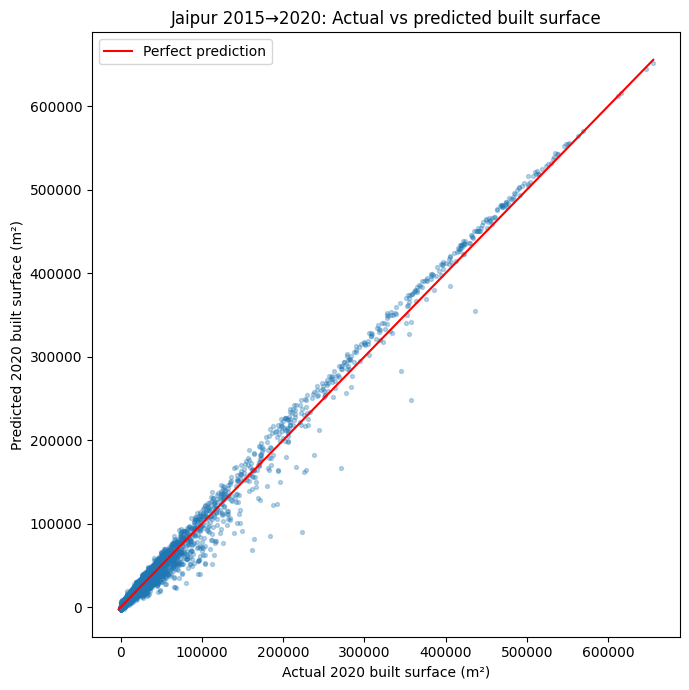

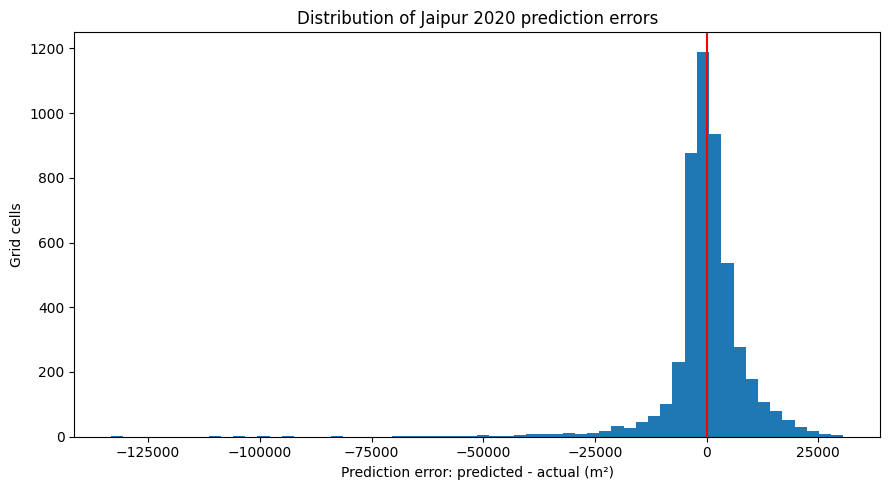

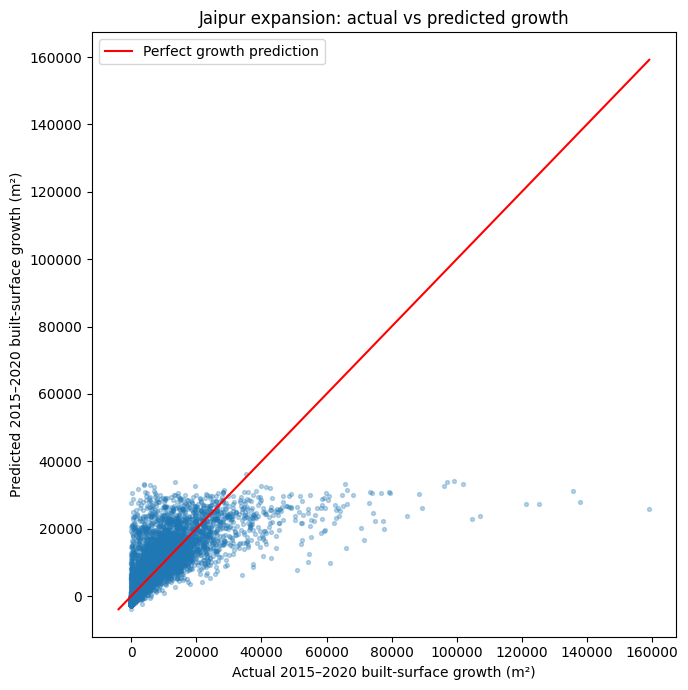

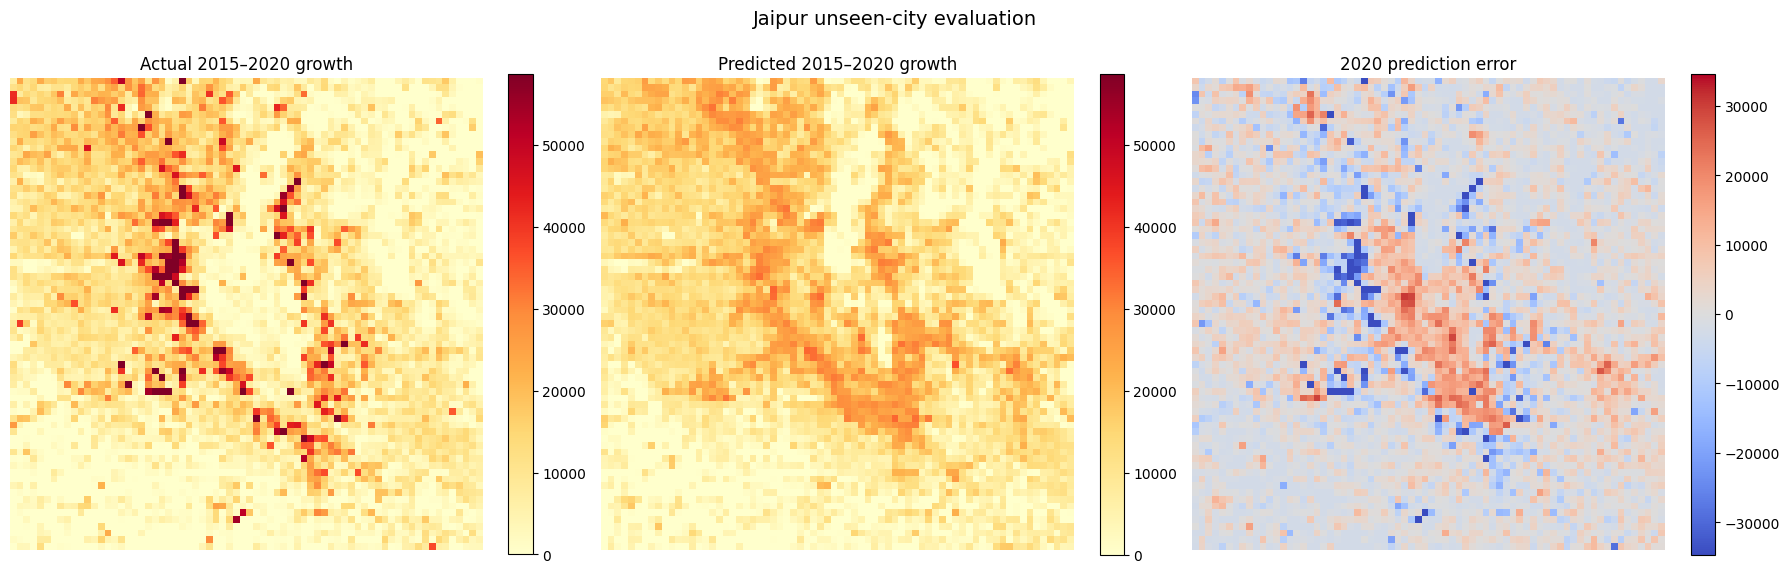

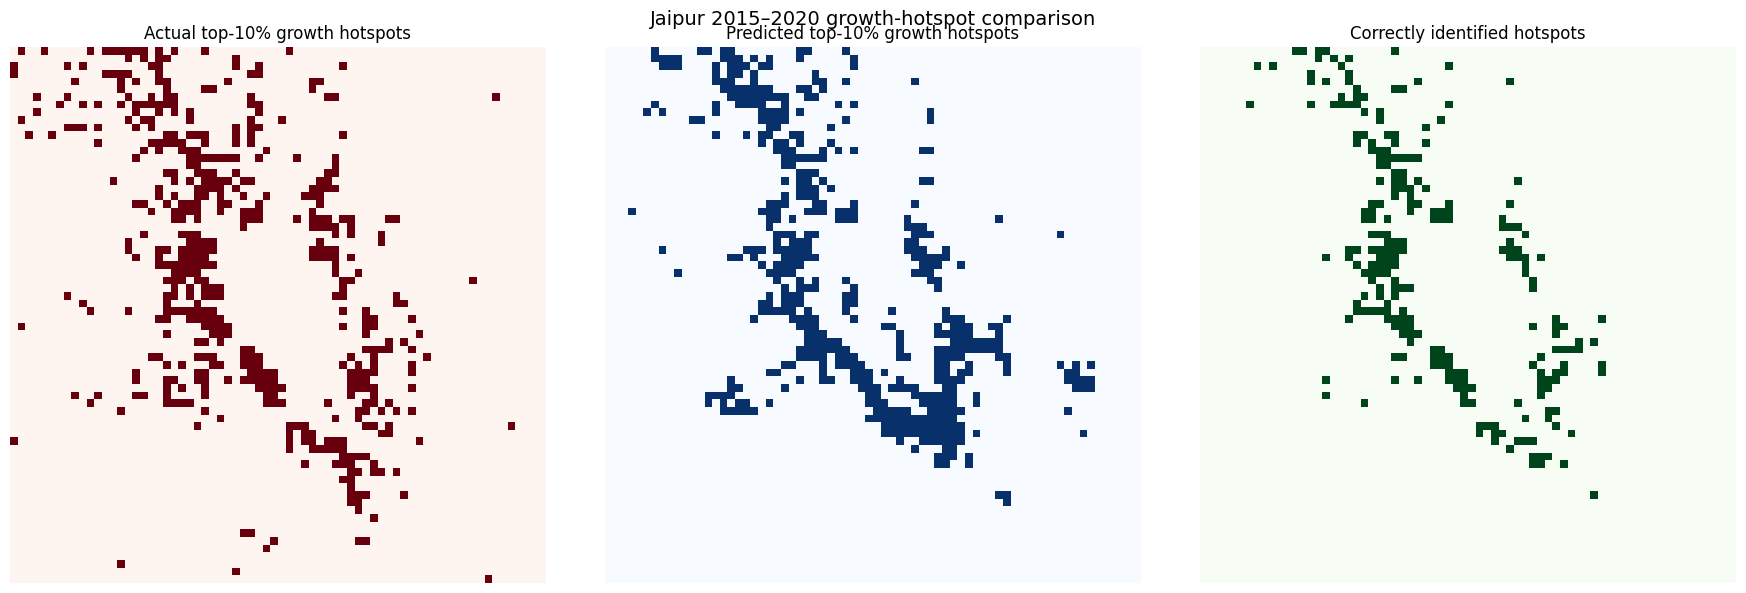


SAVED COMPARISON ARTIFACTS
Enriched cell comparison: /content/drive/MyDrive/GHSL_Urban_Growth_Model/jaipur_unseen_city_evaluation_v1/jaipur_2015_2020_actual_vs_predicted_enriched.csv
Comparison summary: /content/drive/MyDrive/GHSL_Urban_Growth_Model/jaipur_unseen_city_evaluation_v1/jaipur_2015_2020_comparison_summary.json
Figures: /content/drive/MyDrive/GHSL_Urban_Growth_Model/jaipur_unseen_city_evaluation_v1/actual_vs_predicted_figures
Figures created: 5
JAIPUR ACTUAL VS PREDICTED COMPARISON: SUCCESS


In [31]:
# ============================================================
# JAIPUR ACTUAL VS PREDICTED COMPARISON
#
# Primary test:
#   Jaipur 2015 features -> predicted 2020 built surface
#
# Compares:
#   - Linear Regression prediction
#   - Actual 2020 built surface
#   - Persistence baseline
#   - Actual versus predicted expansion
#   - Top-10% expansion hotspots
#
# Reads existing Google Drive artifacts only.
# Does not rerun Spark, train models, or modify HDFS.
# ============================================================

from pathlib import Path
from IPython.display import display

import json
import numpy as np
import pandas as pd
import matplotlib.pyplot as plt


# ============================================================
# PATHS
# ============================================================

RESULT_ROOT = Path(
    "/content/drive/MyDrive/"
    "GHSL_Urban_Growth_Model/"
    "jaipur_unseen_city_evaluation_v1"
)

PREDICTION_PATH = (
    RESULT_ROOT
    / "jaipur_2015_2020_cell_predictions.csv"
)

METRICS_PATH = (
    RESULT_ROOT
    / "jaipur_transition_metrics.csv"
)

FIGURE_ROOT = (
    RESULT_ROOT
    / "actual_vs_predicted_figures"
)

FIGURE_ROOT.mkdir(
    parents=True,
    exist_ok=True,
)


if not PREDICTION_PATH.is_file():
    raise FileNotFoundError(
        "Prediction CSV is missing: "
        + str(PREDICTION_PATH)
    )


if not METRICS_PATH.is_file():
    raise FileNotFoundError(
        "Transition-metrics CSV is missing: "
        + str(METRICS_PATH)
    )


# ============================================================
# LOAD RESULTS
# ============================================================

predictions = pd.read_csv(
    PREDICTION_PATH
)

transition_metrics = pd.read_csv(
    METRICS_PATH
)


required_prediction_columns = {
    "grid_cell_id",
    "grid_1km_row",
    "grid_1km_col",
    "grid_min_x",
    "grid_max_x",
    "grid_min_y",
    "grid_max_y",
    "from_epoch",
    "to_epoch",
    "current_built_surface_m2",
    "label",
    "model_prediction",
    "persistence_prediction",
    "actual_growth_m2",
    "predicted_growth_m2",
    "model_error",
    "model_abs_error",
}


missing_columns = sorted(
    required_prediction_columns
    - set(
        predictions.columns
    )
)


if missing_columns:
    raise RuntimeError(
        "Prediction CSV is missing columns: "
        + repr(missing_columns)
    )


if len(predictions) != 4900:
    raise RuntimeError(
        "Expected 4,900 Jaipur test cells, found "
        + str(len(predictions))
    )


if set(
    predictions[
        "from_epoch"
    ].unique()
) != {2015}:
    raise RuntimeError(
        "Prediction CSV does not contain only "
        "the 2015 source epoch."
    )


if set(
    predictions[
        "to_epoch"
    ].unique()
) != {2020}:
    raise RuntimeError(
        "Prediction CSV does not contain only "
        "the 2020 target epoch."
    )


# ============================================================
# RECOMPUTE METRICS FROM CELL-LEVEL RESULTS
# ============================================================

actual = (
    predictions[
        "label"
    ].astype(float)
)

model_prediction = (
    predictions[
        "model_prediction"
    ].astype(float)
)

persistence_prediction = (
    predictions[
        "persistence_prediction"
    ].astype(float)
)

actual_growth = (
    predictions[
        "actual_growth_m2"
    ].astype(float)
)

predicted_growth = (
    predictions[
        "predicted_growth_m2"
    ].astype(float)
)


def regression_metrics(
    observed,
    predicted,
):
    residual = (
        predicted
        - observed
    )

    mae = np.mean(
        np.abs(
            residual
        )
    )

    rmse = np.sqrt(
        np.mean(
            residual ** 2
        )
    )

    denominator = np.sum(
        (
            observed
            - observed.mean()
        )
        ** 2
    )

    r2 = (
        1.0
        - (
            np.sum(
                residual ** 2
            )
            / denominator
        )
    )

    bias = np.mean(
        residual
    )

    median_absolute_error = np.median(
        np.abs(
            residual
        )
    )

    return {
        "MAE (m²)": mae,
        "RMSE (m²)": rmse,
        "R²": r2,
        "Bias (m²)": bias,
        "Median absolute error (m²)": (
            median_absolute_error
        ),
    }


model_metrics = regression_metrics(
    actual,
    model_prediction,
)

persistence_metrics = regression_metrics(
    actual,
    persistence_prediction,
)


comparison_table = pd.DataFrame(
    [
        {
            "Method": (
                "Six-city Linear Regression"
            ),
            **model_metrics,
        },
        {
            "Method": (
                "Persistence baseline"
            ),
            **persistence_metrics,
        },
    ]
)


comparison_table[
    "MAE rank"
] = comparison_table[
    "MAE (m²)"
].rank(
    method="min"
).astype(int)


comparison_table[
    "RMSE rank"
] = comparison_table[
    "RMSE (m²)"
].rank(
    method="min"
).astype(int)


comparison_table[
    "R² rank"
] = comparison_table[
    "R²"
].rank(
    method="min",
    ascending=False,
).astype(int)


print(
    "============================================================"
)

print(
    "JAIPUR 2015 -> 2020: ACTUAL VS PREDICTED"
)

print(
    "============================================================"
)

print(
    "Grid cells:",
    len(predictions),
)

print(
    "Model used Jaipur during training: NO"
)

print(
    "Source epoch: 2015"
)

print(
    "Actual target epoch: 2020"
)

print()


display(
    comparison_table.style.format(
        {
            "MAE (m²)": "{:,.2f}",
            "RMSE (m²)": "{:,.2f}",
            "R²": "{:.6f}",
            "Bias (m²)": "{:+,.2f}",
            "Median absolute error (m²)": (
                "{:,.2f}"
            ),
        }
    )
)


# ============================================================
# IMPROVEMENT OVER PERSISTENCE
# ============================================================

mae_improvement = (
    (
        persistence_metrics[
            "MAE (m²)"
        ]
        - model_metrics[
            "MAE (m²)"
        ]
    )
    / persistence_metrics[
        "MAE (m²)"
    ]
    * 100.0
)


rmse_improvement = (
    (
        persistence_metrics[
            "RMSE (m²)"
        ]
        - model_metrics[
            "RMSE (m²)"
        ]
    )
    / persistence_metrics[
        "RMSE (m²)"
    ]
    * 100.0
)


print()
print(
    "============================================================"
)

print(
    "IMPROVEMENT OVER PERSISTENCE"
)

print(
    "============================================================"
)

print(
    "MAE improvement:",
    f"{mae_improvement:+.2f}%",
)

print(
    "RMSE improvement:",
    f"{rmse_improvement:+.2f}%",
)

print(
    "Positive values mean the trained model "
    "performed better than persistence."
)


# ============================================================
# ACTUAL AND PREDICTED GROWTH COMPARISON
# ============================================================

growth_metrics = regression_metrics(
    actual_growth,
    predicted_growth,
)


growth_summary = pd.DataFrame(
    [
        {
            "Measure": (
                "Actual 2015–2020 growth"
            ),
            "Mean (m²)": (
                actual_growth.mean()
            ),
            "Median (m²)": (
                actual_growth.median()
            ),
            "Total (m²)": (
                actual_growth.sum()
            ),
        },
        {
            "Measure": (
                "Predicted 2015–2020 growth"
            ),
            "Mean (m²)": (
                predicted_growth.mean()
            ),
            "Median (m²)": (
                predicted_growth.median()
            ),
            "Total (m²)": (
                predicted_growth.sum()
            ),
        },
    ]
)


print()
print(
    "============================================================"
)

print(
    "ACTUAL VS PREDICTED JAIPUR EXPANSION"
)

print(
    "============================================================"
)


display(
    growth_summary.style.format(
        {
            "Mean (m²)": "{:,.2f}",
            "Median (m²)": "{:,.2f}",
            "Total (m²)": "{:,.0f}",
        }
    )
)


print(
    "Growth MAE:",
    f'{growth_metrics["MAE (m²)"]:,.2f} m²',
)

print(
    "Growth RMSE:",
    f'{growth_metrics["RMSE (m²)"]:,.2f} m²',
)

print(
    "Growth bias:",
    f'{growth_metrics["Bias (m²)"]:+,.2f} m²',
)


# ============================================================
# TOP-10% GROWTH-HOTSPOT COMPARISON
# ============================================================

hotspot_count = int(
    round(
        len(predictions)
        * 0.10
    )
)


actual_hotspot_indices = set(
    predictions.nlargest(
        hotspot_count,
        "actual_growth_m2",
    ).index
)


predicted_hotspot_indices = set(
    predictions.nlargest(
        hotspot_count,
        "predicted_growth_m2",
    ).index
)


correct_hotspots = (
    actual_hotspot_indices
    & predicted_hotspot_indices
)


hotspot_precision = (
    len(correct_hotspots)
    / len(predicted_hotspot_indices)
)


hotspot_recall = (
    len(correct_hotspots)
    / len(actual_hotspot_indices)
)


hotspot_f1 = (
    0.0
    if (
        hotspot_precision
        + hotspot_recall
        == 0
    )
    else (
        2.0
        * hotspot_precision
        * hotspot_recall
        / (
            hotspot_precision
            + hotspot_recall
        )
    )
)


predictions[
    "actual_top10_hotspot"
] = predictions.index.isin(
    actual_hotspot_indices
)

predictions[
    "predicted_top10_hotspot"
] = predictions.index.isin(
    predicted_hotspot_indices
)

predictions[
    "correct_top10_hotspot"
] = predictions.index.isin(
    correct_hotspots
)


print()
print(
    "============================================================"
)

print(
    "TOP-10% GROWTH-HOTSPOT COMPARISON"
)

print(
    "============================================================"
)

print(
    "Actual hotspot cells:",
    len(actual_hotspot_indices),
)

print(
    "Predicted hotspot cells:",
    len(predicted_hotspot_indices),
)

print(
    "Correctly identified hotspot cells:",
    len(correct_hotspots),
)

print(
    "Precision:",
    f"{hotspot_precision:.2%}",
)

print(
    "Recall:",
    f"{hotspot_recall:.2%}",
)

print(
    "F1:",
    f"{hotspot_f1:.2%}",
)

print(
    "Random-ranking reference:",
    "approximately 10%",
)


# ============================================================
# ERROR DISTRIBUTION BY DECILE
# ============================================================

predictions[
    "actual_built_surface_decile"
] = pd.qcut(
    actual.rank(
        method="first"
    ),
    q=10,
    labels=[
        "D1",
        "D2",
        "D3",
        "D4",
        "D5",
        "D6",
        "D7",
        "D8",
        "D9",
        "D10",
    ],
)


error_by_decile = (
    predictions
    .groupby(
        "actual_built_surface_decile",
        observed=True,
    )
    .agg(
        cells=(
            "grid_cell_id",
            "count",
        ),
        actual_mean_m2=(
            "label",
            "mean",
        ),
        predicted_mean_m2=(
            "model_prediction",
            "mean",
        ),
        mae_m2=(
            "model_abs_error",
            "mean",
        ),
        signed_error_m2=(
            "model_error",
            "mean",
        ),
    )
    .reset_index()
)


print()
print(
    "============================================================"
)

print(
    "ERROR BY ACTUAL 2020 BUILT-SURFACE DECILE"
)

print(
    "D1 = lowest-built cells; D10 = highest-built cells"
)

print(
    "============================================================"
)


display(
    error_by_decile.style.format(
        {
            "actual_mean_m2": "{:,.2f}",
            "predicted_mean_m2": "{:,.2f}",
            "mae_m2": "{:,.2f}",
            "signed_error_m2": "{:+,.2f}",
        }
    )
)


# ============================================================
# FIGURE 1: OBSERVED VS PREDICTED BUILT SURFACE
# ============================================================

plt.figure(
    figsize=(
        7,
        7,
    )
)

plt.scatter(
    actual,
    model_prediction,
    s=8,
    alpha=0.3,
)

minimum_value = min(
    actual.min(),
    model_prediction.min(),
)

maximum_value = max(
    actual.max(),
    model_prediction.max(),
)

plt.plot(
    [
        minimum_value,
        maximum_value,
    ],
    [
        minimum_value,
        maximum_value,
    ],
    color="red",
    linewidth=1.5,
    label="Perfect prediction",
)

plt.xlabel(
    "Actual 2020 built surface (m²)"
)

plt.ylabel(
    "Predicted 2020 built surface (m²)"
)

plt.title(
    "Jaipur 2015→2020: Actual vs predicted built surface"
)

plt.legend()

plt.tight_layout()

plt.savefig(
    FIGURE_ROOT
    / "jaipur_actual_vs_predicted_2020.png",
    dpi=200,
)

plt.show()

plt.close()


# ============================================================
# FIGURE 2: RESIDUAL DISTRIBUTION
# ============================================================

plt.figure(
    figsize=(
        9,
        5,
    )
)

plt.hist(
    predictions[
        "model_error"
    ],
    bins=60,
)

plt.axvline(
    0,
    color="red",
    linewidth=1.5,
)

plt.xlabel(
    "Prediction error: predicted - actual (m²)"
)

plt.ylabel(
    "Grid cells"
)

plt.title(
    "Distribution of Jaipur 2020 prediction errors"
)

plt.tight_layout()

plt.savefig(
    FIGURE_ROOT
    / "jaipur_2020_error_distribution.png",
    dpi=200,
)

plt.show()

plt.close()


# ============================================================
# FIGURE 3: ACTUAL VS PREDICTED GROWTH
# ============================================================

plt.figure(
    figsize=(
        7,
        7,
    )
)

plt.scatter(
    actual_growth,
    predicted_growth,
    s=8,
    alpha=0.3,
)

growth_minimum = min(
    actual_growth.min(),
    predicted_growth.min(),
)

growth_maximum = max(
    actual_growth.max(),
    predicted_growth.max(),
)

plt.plot(
    [
        growth_minimum,
        growth_maximum,
    ],
    [
        growth_minimum,
        growth_maximum,
    ],
    color="red",
    linewidth=1.5,
    label="Perfect growth prediction",
)

plt.xlabel(
    "Actual 2015–2020 built-surface growth (m²)"
)

plt.ylabel(
    "Predicted 2015–2020 built-surface growth (m²)"
)

plt.title(
    "Jaipur expansion: actual vs predicted growth"
)

plt.legend()

plt.tight_layout()

plt.savefig(
    FIGURE_ROOT
    / "jaipur_actual_vs_predicted_growth.png",
    dpi=200,
)

plt.show()

plt.close()


# ============================================================
# FIGURE 4: SPATIAL ACTUAL/PREDICTED/ERROR MAPS
# ============================================================

map_data = (
    predictions
    .sort_values(
        [
            "grid_1km_row",
            "grid_1km_col",
        ]
    )
)


actual_pivot = (
    map_data
    .pivot(
        index="grid_1km_row",
        columns="grid_1km_col",
        values="actual_growth_m2",
    )
    .sort_index(
        ascending=False
    )
)


predicted_pivot = (
    map_data
    .pivot(
        index="grid_1km_row",
        columns="grid_1km_col",
        values="predicted_growth_m2",
    )
    .sort_index(
        ascending=False
    )
)


error_pivot = (
    map_data
    .pivot(
        index="grid_1km_row",
        columns="grid_1km_col",
        values="model_error",
    )
    .sort_index(
        ascending=False
    )
)


growth_limit = max(
    abs(
        np.nanpercentile(
            actual_pivot.values,
            99,
        )
    ),
    abs(
        np.nanpercentile(
            predicted_pivot.values,
            99,
        )
    ),
)


error_limit = max(
    abs(
        np.nanpercentile(
            error_pivot.values,
            1,
        )
    ),
    abs(
        np.nanpercentile(
            error_pivot.values,
            99,
        )
    ),
)


figure, axes = plt.subplots(
    1,
    3,
    figsize=(
        18,
        6,
    ),
)


actual_image = axes[
    0
].imshow(
    actual_pivot.values,
    cmap="YlOrRd",
    vmin=0,
    vmax=growth_limit,
)

axes[
    0
].set_title(
    "Actual 2015–2020 growth"
)

axes[
    0
].set_axis_off()

figure.colorbar(
    actual_image,
    ax=axes[
        0
    ],
    fraction=0.046,
)


predicted_image = axes[
    1
].imshow(
    predicted_pivot.values,
    cmap="YlOrRd",
    vmin=0,
    vmax=growth_limit,
)

axes[
    1
].set_title(
    "Predicted 2015–2020 growth"
)

axes[
    1
].set_axis_off()

figure.colorbar(
    predicted_image,
    ax=axes[
        1
    ],
    fraction=0.046,
)


error_image = axes[
    2
].imshow(
    error_pivot.values,
    cmap="coolwarm",
    vmin=-error_limit,
    vmax=error_limit,
)

axes[
    2
].set_title(
    "2020 prediction error"
)

axes[
    2
].set_axis_off()

figure.colorbar(
    error_image,
    ax=axes[
        2
    ],
    fraction=0.046,
)


figure.suptitle(
    "Jaipur unseen-city evaluation",
    fontsize=14,
)

plt.tight_layout()

plt.savefig(
    FIGURE_ROOT
    / "jaipur_spatial_actual_predicted_error.png",
    dpi=200,
)

plt.show()

plt.close()


# ============================================================
# FIGURE 5: HOTSPOT MAPS
# ============================================================

actual_hotspot_pivot = (
    predictions
    .pivot(
        index="grid_1km_row",
        columns="grid_1km_col",
        values="actual_top10_hotspot",
    )
    .sort_index(
        ascending=False
    )
)


predicted_hotspot_pivot = (
    predictions
    .pivot(
        index="grid_1km_row",
        columns="grid_1km_col",
        values="predicted_top10_hotspot",
    )
    .sort_index(
        ascending=False
    )
)


correct_hotspot_pivot = (
    predictions
    .pivot(
        index="grid_1km_row",
        columns="grid_1km_col",
        values="correct_top10_hotspot",
    )
    .sort_index(
        ascending=False
    )
)


figure, axes = plt.subplots(
    1,
    3,
    figsize=(
        18,
        6,
    ),
)


axes[
    0
].imshow(
    actual_hotspot_pivot.values,
    cmap="Reds",
    vmin=0,
    vmax=1,
)

axes[
    0
].set_title(
    "Actual top-10% growth hotspots"
)

axes[
    0
].set_axis_off()


axes[
    1
].imshow(
    predicted_hotspot_pivot.values,
    cmap="Blues",
    vmin=0,
    vmax=1,
)

axes[
    1
].set_title(
    "Predicted top-10% growth hotspots"
)

axes[
    1
].set_axis_off()


axes[
    2
].imshow(
    correct_hotspot_pivot.values,
    cmap="Greens",
    vmin=0,
    vmax=1,
)

axes[
    2
].set_title(
    "Correctly identified hotspots"
)

axes[
    2
].set_axis_off()


figure.suptitle(
    "Jaipur 2015–2020 growth-hotspot comparison",
    fontsize=14,
)

plt.tight_layout()

plt.savefig(
    FIGURE_ROOT
    / "jaipur_hotspot_comparison.png",
    dpi=200,
)

plt.show()

plt.close()


# ============================================================
# SAVE ENRICHED CELL COMPARISON AND SUMMARY
# ============================================================

comparison_csv_path = (
    RESULT_ROOT
    / "jaipur_2015_2020_actual_vs_predicted_enriched.csv"
)


predictions.to_csv(
    comparison_csv_path,
    index=False,
)


comparison_summary = {
    "city": (
        "Jaipur Metropolitan Region"
    ),
    "source_epoch": 2015,
    "actual_target_epoch": 2020,
    "grid_cells": int(
        len(predictions)
    ),
    "jaipur_used_in_training": False,
    "model": (
        "Six-city Linear Regression"
    ),
    "model_metrics": (
        model_metrics
    ),
    "persistence_metrics": (
        persistence_metrics
    ),
    "mae_improvement_vs_persistence_percent": (
        mae_improvement
    ),
    "rmse_improvement_vs_persistence_percent": (
        rmse_improvement
    ),
    "growth_metrics": (
        growth_metrics
    ),
    "actual_growth_total_m2": float(
        actual_growth.sum()
    ),
    "predicted_growth_total_m2": float(
        predicted_growth.sum()
    ),
    "hotspot_count": int(
        hotspot_count
    ),
    "correct_hotspots": int(
        len(correct_hotspots)
    ),
    "hotspot_precision": float(
        hotspot_precision
    ),
    "hotspot_recall": float(
        hotspot_recall
    ),
    "hotspot_f1": float(
        hotspot_f1
    ),
    "random_hotspot_reference": 0.10,
}


summary_path = (
    RESULT_ROOT
    / "jaipur_2015_2020_comparison_summary.json"
)


summary_path.write_text(
    json.dumps(
        comparison_summary,
        indent=2,
        sort_keys=True,
    )
    + "\n",
    encoding="utf-8",
)


print()
print(
    "============================================================"
)

print(
    "SAVED COMPARISON ARTIFACTS"
)

print(
    "============================================================"
)

print(
    "Enriched cell comparison:",
    comparison_csv_path,
)

print(
    "Comparison summary:",
    summary_path,
)

print(
    "Figures:",
    FIGURE_ROOT,
)

print(
    "Figures created:",
    len(
        list(
            FIGURE_ROOT.glob(
                "*.png"
            )
        )
    ),
)

print(
    "JAIPUR ACTUAL VS PREDICTED COMPARISON: SUCCESS"
)